# Pokémon — Des sources à la base finale

**Question :** les formes introduites dans les générations récentes présentent-elles des statistiques de base plus élevées ou plus spécialisées, à catégories comparables ?

Ce notebook rassemble la collecte, la compréhension des sources et la préparation. Le parcours suit **observation → explication → décision → vérification**. Il produit la base nécessaire à l’analyse, sans encore répondre à la question scientifique.

Une ligne représentera une **forme PokéAPI**. Toutes les formes sont conservées, y compris cosmétiques, régionales, Méga, Gigamax et historiques. Les identifiants de variété et d’espèce permettent ensuite de changer de niveau d’analyse. Les talents et conditions d’évolution restent hors périmètre.

Exécuter les cellules dans l’ordre depuis la racine du projet ou `notebook/`. Le code détaillé reste dans les trois modules `src/collect.py`, `src/exploration.py` et `src/preparation.py`. Les configurations sont dans `config/`. Les résultats commentés correspondent aux instantanés `reference_01` et `api_01` ; une actualisation doit être vérifiée à nouveau.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

project_dir = Path.cwd()
if project_dir.name == "notebook":
    project_dir = project_dir.parent
assert (project_dir / "src" / "collect.py").exists(), "Ouvrir depuis le projet ou notebook/."
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

from src import collect, exploration as eda, preparation as prep

## 1. Charger les sources et contrôler leurs clés

PokéAPI décrit les espèces, variétés, formes, statistiques, types et groupes de jeux. Showdown servira à **vérifier les correspondances après fusion** et à enrichir les catégories et tiers. Les statuts légendaire/fabuleux existent déjà dans PokéAPI.

Les dix CSV PokéAPI proviennent d’une révision figée ; le JSON Showdown est une copie datée. La collecte conserve les sources séparées et vérifie leurs empreintes. Les contrôles portent sur les clés, les relations entre tables et les six statistiques. Une égalité de statistiques n’est pas un contrôle d’unicité des formes.

In [2]:
collect.collect_sources()
data = collect.load_sources()
display(collect.check_sources(data))
showdown = data["showdown_pokedex"]

Téléchargé : pokemon_species.csv
Téléchargé : pokemon.csv
Téléchargé : pokemon_stats.csv
Téléchargé : stats.csv
Téléchargé : pokemon_species_names.csv
Téléchargé : pokemon_types.csv
Téléchargé : type_names.csv
Téléchargé : showdown_pokedex.json
Téléchargé : pokemon_forms.csv
Téléchargé : pokemon_form_types.csv
Téléchargé : version_groups.csv
Contrôles terminés : 1579 formes conservées ; aucun filtre ni regroupement.


,source,lignes_ou_fiches
0,pokemon_species,1025
1,pokemon,1351
2,pokemon_stats,8106
3,stats,9
4,pokemon_species_names,12300
5,pokemon_types,2116
6,type_names,232
7,showdown_pokedex,1518
8,pokemon_forms,1579
9,pokemon_form_types,35


## 2. Espèce, variété, forme : quelle unité conserver ?

Une espèce peut contenir plusieurs variétés, et une variété plusieurs formes. Les statistiques sont stockées au niveau de la **variété**. Nous les rattachons aux formes sans multiplier ni supprimer leurs identifiants. Les exemples illustrent la structure ; les fonctions traitent l’ensemble des observations.

In [3]:
forms = eda.explore_forms(data)
display(eda.summarize_forms(forms))
species = eda.summarize_species(forms)
display(species.loc[species["species_id"].isin([493, 669, 745, 773, 925, 1007, 1008])])

,nombre
Formes,1579
Identifiants de forme distincts,1579
Variétés représentées,1351
Espèces représentées,1025
Formes non définies par défaut,236
Formes Gigamax,34
Variétés sans forme par défaut,8
Formes avec une statistique manquante,0
Formes sans génération renseignée,0
Formes datées avant leur espèce,0


,species_id,species_name,forms,varieties
492,493,arceus,19,1
668,669,flabebe,5,1
744,745,lycanroc,3,3
772,773,silvally,18,1
924,925,maushold,2,2
1006,1007,koraidon,5,5
1007,1008,miraidon,5,5


**Constat :** 1 579 formes, 1 351 variétés et 1 025 espèces. Flabébé a cinq formes pour une variété ; Lougaroc a trois formes pour trois variétés. Arceus a 19 formes et Silvallié 18, chacun pour une seule variété.

**Décision :** conserver le détail, notamment les 236 formes non définies par défaut et les 34 Gigamax. Les huit variétés de déplacement de Koraidon/Miraidon n’ont pas de forme marquée par défaut : filtrer sur ce statut les ferait disparaître.

### Statistiques identiques et générations différentes

Les générations des formes viennent de leurs groupes de jeux d’introduction. La génération de l’espèce reste distincte : elle ne date pas automatiquement ses formes régionales ou Méga.

In [4]:
examples = ["charizard", "charizard-mega-x", "charizard-gmax", "lycanroc-midday",
            "lycanroc-midnight", "lycanroc-dusk", "maushold-family-of-four",
            "maushold-family-of-three", "arceus-normal", "arceus-fairy"]
display(forms.loc[forms["form_name"].isin(examples),
    ["form_name", "pokemon_id", "form_generation", "species_generation"] + eda.STAT_COLUMNS])

,form_name,pokemon_id,form_generation,species_generation,hp,attack,defense,special-attack,special-defense,speed
5,charizard,6,1,1,78,84,78,109,85,100
492,arceus-normal,493,4,4,120,120,120,120,120,120
744,lycanroc-midday,745,7,7,75,115,65,55,65,112
924,maushold-family-of-four,925,9,9,74,75,70,65,75,111
1109,arceus-fairy,493,6,4,120,120,120,120,120,120
1158,charizard-mega-x,10034,6,1,78,130,111,130,85,100
1252,lycanroc-midnight,10126,7,7,85,115,75,55,75,82
1335,lycanroc-dusk,10152,7,7,75,117,65,55,65,110
1389,charizard-gmax,10196,8,1,78,84,78,109,85,100
1450,maushold-family-of-three,10257,9,9,74,75,70,65,75,111


**Explication :** Lougaroc présente des profils différents selon ses variétés ; Famignol partage ses statistiques entre deux variétés. Dracaufeu et sa forme Gigamax ont les mêmes statistiques, mais des introductions en générations 1 et 8. Arceus Fée est introduit après Arceus Normal tout en partageant sa variété.

**Conclusion :** des statistiques identiques ne sont pas des doublons de clé. Nous ne fusionnons aucune forme. Les six statistiques sont celles de l’instantané actuel, pas nécessairement celles de l’introduction.

## 3. Comprendre les types avant de les assembler

La table des types de forme est partielle. La recherche suivante repère toutes les variétés concernées, puis affiche quelques exemples pour comprendre la règle.

In [5]:
form_types = eda.inspect_form_types(forms)
print("Formes avec types explicites :", forms["explicit_form_types"].notna().sum())
type_examples = ["arceus-normal", "arceus-fairy", "arceus-unknown", "silvally-normal", "silvally-fairy"]
display(form_types.loc[form_types["form_name"].isin(type_examples)])

Formes avec types explicites : 35


,form_id,form_name,pokemon_id,variety_types,explicit_form_types
492,493,arceus-normal,493,"(Normal,)",NaN
772,773,silvally-normal,773,"(Normal,)",NaN
1081,10057,arceus-unknown,493,"(Normal,)","(???,)"
1109,10085,arceus-fairy,493,"(Normal,)","(Fairy,)"
1272,10248,silvally-fairy,773,"(Normal,)","(Fairy,)"


**Constat :** 35 formes ont un type explicite ; les 1 544 autres disposent de types au niveau de leur variété. Arceus et Silvallié sont retrouvés par la règle générale. Le type Normal n’est pas répété dans la table des formes ; `???` pour `arceus-unknown` est une valeur explicite, distincte d’un `NaN`.

**Règle retenue pour la préparation :** prendre les types explicites de forme lorsqu’ils existent, sinon ceux de la variété. L’entrée historique `arceus-unknown` reste dans l’inventaire ; une analyse des types jouables devra la distinguer explicitement.

## 4. Comprendre les valeurs manquantes de PokéAPI

Le relevé complet reste visible ci-dessous. On examine ensuite les absences qui pourraient affecter le choix des observations et des variables, plutôt que de supprimer toutes les lignes incomplètes.

In [6]:
display(eda.missing_pokeapi(data))
missing_context = eda.missing_pokeapi_context(data)
display(missing_context["habitat"])
display(missing_context["varieties"])
display(missing_context["translations"].loc[[5, 9]])

,table,champ,lignes,manquantes,texte_vide,pourcentage_manquant
0,pokemon_species,evolves_from_species_id,1025,541,0,52.8
1,pokemon_species,habitat_id,1025,639,0,62.3
2,pokemon_species,conquest_order,1025,825,0,80.5
3,pokemon,base_experience,1351,49,0,3.6
4,pokemon,order,1351,139,0,10.3
5,stats,damage_class_id,9,4,0,44.4
6,stats,game_index,9,2,0,22.2
7,pokemon_species_names,genus,12300,1535,0,12.5
8,pokemon_forms,form_identifier,1579,961,0,60.9


,especes,habitats_absents
generation_id,,
1,151,0
2,100,0
3,135,0
4,107,107
5,156,156
6,72,72
7,88,88
8,96,96
9,120,120


,varietes,experiences_absentes,ordres_absents
is_default,,,
0,326,49,132
1,1025,0,7


,lignes,noms_absents,descriptions_absentes
local_language_id,,,
5,1025,0,0
9,1025,0,0


| Observation | Explication et décision |
|---|---|
| 639 habitats absents | Toutes les espèces des générations IV à IX sont concernées. Ce champ n’est pas retenu pour comparer les générations ; aucune imputation. |
| 49 expériences de base absentes | Uniquement des variétés non définies par défaut. Cause précise non établie ; champ non nécessaire aux six statistiques, valeurs laissées manquantes. |
| 961 noms courts de forme absents | Les identifiants complets existent : les utiliser, sans supprimer de formes ni inventer un suffixe. |
| Traductions et descriptions variables selon la langue | Sélectionner explicitement le nom français et la catégorie anglaise, complets ici. Ne pas inventer de traduction. |
| Ordres d’affichage, liens évolutifs et métadonnées de statistiques incomplets | Ils ne définissent ni la clé de forme ni une absence parmi les six statistiques étudiées. Ils restent dans les sources, hors des variables finales. |

**Conclusion :** distinguer information non applicable, disponible ailleurs et véritable lacune. Une suppression générale des valeurs manquantes éliminerait des générations entières sur la seule base de leur habitat. Les champs sont décrits dans la [documentation PokéAPI](https://pokeapi.co/docs/v2).

## 5. Comprendre Showdown avant la fusion

Les absences ci-dessous concernent les **1 518 fiches Showdown**, pas encore la couverture des formes PokéAPI. Nous distinguons champ omis, valeur nulle et contenu vide, puis examinons les références entre fiches sans imputer de valeur à ce stade.

In [7]:
display(eda.missing_showdown(showdown))
references = eda.inspect_showdown_references(showdown)
display(references["summary"])
display(references["tier_conflicts"])

,champ,fiches,champ_absent,valeur_nulle,contenu_vide
0,num,1518,37,0,0
1,baseStats,1518,37,0,0
2,types,1518,37,0,0
3,heightm,1518,37,0,0
4,weightkg,1518,37,0,0
5,tags,1518,1358,0,0
6,tier,1518,102,0,0
7,gen,1518,1351,0,0
8,baseSpecies,1518,1121,0,0
9,forme,1518,1121,0,0


,nombre
Fiches avec un champ commun absent,37
Dont explicitement cosmétiques,37
Dont référence contenant les cinq champs,37
Fiches sans tier explicite,102
Dont tier disponible dans baseSpecies,102
Désaccords entre références de tier,2
Fiches sans champ tags,1358
Dont référence contenant des tags,94
Fiches étiquetées Paradox,16
Fiches étiquetées Ultra Beast,11


,cle,baseSpecies,battleOnly,tier_base,tier_combat
99,ogerponhearthflametera,Ogerpon,Ogerpon-Hearthflame,OU,Uber
100,ogerponcornerstonetera,Ogerpon,Ogerpon-Cornerstone,OU,UUBL


**Constats et explications :** les 37 fiches qui omettent numéro/statistiques/types sont explicitement cosmétiques et renvoient à des fiches complètes. Un héritage documenté est possible dans ces cas. Pour les 102 tiers absents, recopier systématiquement `baseSpecies` serait incorrect : les références de combat d’Ogerpon peuvent porter un autre tier. La préparation suivra les références pertinentes et conservera leur origine.

Les tags sont absents de 1 358 fiches. Cette absence ne prouve pas une catégorie négative ; la génération explicite manque aussi souvent et sera obtenue via PokéAPI. `Illegal` est un statut de contexte, pas une valeur manquante ni un motif général d’exclusion. Les règles d’héritage sont décrites dans le [moteur Showdown](https://github.com/smogon/pokemon-showdown/blob/master/sim/dex-species.ts).

### Pourquoi ne pas choisir la correspondance à partir des statistiques ?

Le diagnostic suivant cherche les fiches partageant le numéro d’espèce et les six statistiques. Il sert uniquement à montrer les ambiguïtés ; il ne sera pas utilisé pour choisir les identités.

In [8]:
candidates = eda.inspect_showdown_candidates(forms, showdown)
display(candidates["summary"])
display(candidates["candidates"].loc[
    candidates["candidates"]["form_name"].isin(["charizard", "charizard-gmax"]),
    ["form_name", "showdown_name"]])

,nombre
Formes sans candidat numérique,0
Formes avec un candidat numérique,1236
Formes avec plusieurs candidats numériques,343


,form_name,showdown_name
6,charizard,Charizard
7,charizard,Charizard-Gmax
2518,charizard-gmax,Charizard
2519,charizard-gmax,Charizard-Gmax


**Constat :** 1 236 formes ont un candidat numérique et 343 en ont plusieurs. Même un candidat unique ne valide pas une identité. Dracaufeu et Gigamax montrent qu’un même profil peut correspondre à des formes différentes.

**Décision :** rapprocher les noms et références déclarées, puis vérifier indépendamment l’espèce, les statistiques et les types. Conserver les formes non rapprochées. L’accord de deux sources ne garantit pas leur indépendance documentaire.

## 6. Obtenir la même table par CSV et par API

Les CSV sont mis en forme selon les décisions précédentes. L’API parcourt toutes les pages de `/pokemon-form/`, indépendamment des identifiants des CSV. Chaque forme référence sa variété (statistiques), son espèce et son groupe de jeux (génération). Ses types sont fournis directement. Aucune limite de génération ni recherche des statistiques par nom de forme.

La première collecte API prend plusieurs minutes. Les réponses sont datées, vérifiées et mises en cache ; une relance les réutilise. Une erreur HTTP interrompt la collecte sans repli silencieux. L’API peut évoluer entre téléchargements, contrairement à la révision CSV figée.

**Comparaison :** 27 colonnes communes, incluant identifiants, noms, générations, statistiques, types et indicateurs. Seuls l’ordre des lignes et les types Python sont harmonisés. Deux absences au même endroit sont égales ; une forme ou valeur présente d’un seul côté constitue un écart. Showdown et les champs bruts hors de ces 27 colonnes ne sont pas comparés.

In [9]:
pokeapi_csv = collect.pokeapi_from_csv(data)
pokeapi_api = collect.collect_pokeapi_api()
comparaison = collect.compare_pokeapi(pokeapi_csv, pokeapi_api)
display(comparaison["resume"])
display(comparaison["ecarts"].head(20))
collection_dir = collect.export_collections(pokeapi_csv, pokeapi_api, comparaison)
assert comparaison["identiques"], "Écarts CSV/API : examiner le rapport avant de poursuivre."
print("Deux collectes équivalentes ; rapport enregistré dans :", collection_dir)

Catalogue API : 1579 formes. Les réponses en cache seront réutilisées.
Formes lues : 100/1579
Formes lues : 200/1579
Formes lues : 300/1579
Formes lues : 400/1579
Formes lues : 500/1579
Formes lues : 600/1579
Formes lues : 700/1579
Formes lues : 800/1579
Formes lues : 900/1579
Formes lues : 1000/1579
Formes lues : 1100/1579
Formes lues : 1200/1579
Formes lues : 1300/1579
Formes lues : 1400/1579
Formes lues : 1500/1579
Formes lues : 1579/1579


,nombre
Formes CSV,1579
Formes API,1579
Formes communes,1579
Formes seulement CSV,0
Formes seulement API,0
Colonnes comparées hors identifiant,26
Cellules différentes sur les formes communes,0


,form_id,champ,csv,api


Deux collectes équivalentes ; rapport enregistré dans : C:\Users\safaa\Documents\ENSAE\S1\Python pour la Data Science\projet python\Projet-python-data-science\data\collected\reference_01_vs_api_01


## 7. Construire la base et ajouter les informations Showdown

**Résultat vérifié pour ces instantanés :** 1 579 formes et 27 colonnes communes, sans écart. On utilise une seule collecte pour la base finale ; les concaténer doublerait les observations.

La fusion s’appuie sur les noms normalisés, `baseForme` / `cosmeticFormes` et les correspondances justifiées dans `config/preparation.json`. Les 63 formes de Charmilly restent distinctes malgré une représentation Showdown sans sucreries. Les sept couleurs de Météno météore restent aussi distinctes malgré une fiche Showdown commune.

Nous préparons une base à partir de chaque collecte et vérifions encore leur égalité. `source_pokeapi` dans la configuration choisit celle à exporter. Aucune donnée PokéAPI n’est remplacée par Showdown.

### Variables finales

| Colonnes | Définition et source |
|---|---|
| `form_id`, `pokemon_id`, `species_id` | Identifiants de la forme (clé unique), de la variété et de l’espèce PokéAPI. |
| `nom_fr`, `forme` | Nom français **de l’espèce**, puis identifiant complet de la forme. Le français des noms de formes n’est pas présent dans les sources collectées : aucune traduction n’est inventée. |
| `generation` | Génération du groupe de jeux d’introduction de **la forme**, indiqué par PokéAPI. |
| `pv`, `attaque`, `defense`, `attaque_speciale`, `defense_speciale`, `vitesse` | Six statistiques de base de la variété à laquelle la forme appartient. |
| `bst` | Somme des six statistiques, pour étudier leur niveau global. |
| `type_1`, `type_2` | Types en français : types propres à la forme lorsqu’ils sont renseignés, sinon types de sa variété. Le second type est vide pour un mono-type. |
| `tag` | Catégories positives identifiées : Légendaire, Fabuleux, Paradoxe, Ultra-Chimère. Plusieurs catégories peuvent coexister, séparées par `; `. |
| `tier` | Champ `tier` de l’instantané Showdown, directement renseigné ou obtenu par une référence documentée. |
| `is_default_form`, `is_battle_only`, `is_mega` | Indicateurs PokéAPI conservés pour décrire la population et permettre des analyses ultérieures à périmètre explicite. |



In [10]:
base_csv, audit_csv = prep.prepare_database(pokeapi_csv, showdown, source="csv")
base_api, audit_api = prep.prepare_database(pokeapi_api, showdown, source="api")
pd.testing.assert_frame_equal(base_csv, base_api)

source = prep.read_preparation_config()["source_pokeapi"]
assert source in ["csv", "api"], "Choisir csv ou api dans config/preparation.json."
if source == "csv":
    pokeapi, base, audit = pokeapi_csv, base_csv, audit_csv
else:
    pokeapi, base, audit = pokeapi_api, base_api, audit_api
print("Bases finales identiques avec les deux collectes. Source retenue :", source)
display(base.head())

Bases finales identiques avec les deux collectes. Source retenue : csv


,form_id,pokemon_id,species_id,nom_fr,forme,generation,pv,attaque,defense,attaque_speciale,defense_speciale,vitesse,type_1,type_2,is_default_form,is_battle_only,is_mega,bst,tag,tier
0,1,1,1,Bulbizarre,bulbasaur,1,45,49,49,65,65,45,Plante,Poison,1,0,0,318,Non étiqueté,LC
1,2,2,2,Herbizarre,ivysaur,1,60,62,63,80,80,60,Plante,Poison,1,0,0,405,Non étiqueté,NFE
2,3,3,3,Florizarre,venusaur,1,80,82,83,100,100,80,Plante,Poison,1,0,0,525,Non étiqueté,ZU
3,4,4,4,Salamèche,charmander,1,39,52,43,60,50,65,Feu,<NA>,1,0,0,309,Non étiqueté,LC
4,5,5,5,Reptincel,charmeleon,1,58,64,58,80,65,80,Feu,<NA>,1,0,0,405,Non étiqueté,NFE


## 8. Vérifier la fusion et sa couverture

L’audit conserve chaque correspondance, sa justification et les sources des informations. Le numéro d’espèce, les statistiques et les types sont vérifiés **après** le rapprochement. Les types anglais Showdown sont traduits en identifiants via le dictionnaire documenté dans la configuration.

Une correspondance divergente ou non vérifiable bloque l’export. Une forme sans correspondance reste présente, avec son enrichissement manquant.

In [11]:
display(prep.summarize_database(base, audit))
display(audit["methode_jointure"].value_counts().rename("formes").to_frame())
checks = ["espece_concordante", "stats_concordantes", "types_concordants"]
divergences = audit.loc[audit[checks].eq(False).any(axis=1),
    ["forme", "showdown_id", "espece_concordante", "stats_divergentes", "types_pokeapi", "types_showdown"]]
display(divergences)

,nombre
Formes conservées,1579
Espèces représentées,1025
Sans nom français,0
Sans génération,0
Sans correspondance Showdown,61
Correspondances à une représentation cosmétique,70
Statistiques comparées,1518
Divergences de statistiques,0
Types comparés,1518
Divergences de types,0


,formes
methode_jointure,
nom_direct,1307
alias_declare_showdown,99
representation_cosmetique,70
non_apparie,61
alias_configure,42


,forme,showdown_id,espece_concordante,stats_divergentes,types_pokeapi,types_showdown


**Constat :** les 1 518 formes rapprochées ont des statistiques et types concordants. Ce sont des lignes PokéAPI comparées, pas autant de fiches Showdown distinctes. Les 61 autres ne sont ni des accords ni des désaccords.

### Interpréter les absences et les catégories finales

Aucun nom français, génération, premier type ou statistique ne manque. Les 777 seconds types vides désignent les mono-types ; `???` reste une valeur explicite.

Les **61 tiers manquants** concernent 43 formes de Papilord/Lépidonille/Pérégrain, 6 formes sexuées de Viskuse/Moyade/Némélios, 8 modes de déplacement de Koraidon/Miraidon, 2 variantes de Zygarde, une de Rocabot et `arceus-unknown`. Les règles actuelles n’établissent pas leur correspondance : cela ne prouve pas leur absence de Showdown. Ces lignes restent présentes, sans tier inventé. Parmi les tiers renseignés, 1 372 sont explicites et 146 viennent de références documentées.

Les catégories légendaire/fabuleux viennent de PokéAPI. La catégorie anglaise `Paradox Pokémon` complète les tags Showdown et identifie 22 espèces ; `Ultra Beast` en identifie 11. Ces catégories d’espèce sont transmises à leurs formes, même sans correspondance Showdown de forme.

**`Non étiqueté` ne garantit pas un Pokémon « ordinaire ».** Koraidon et Miraidon sont légendaires et Paradoxes : les catégories peuvent se cumuler. Les sources sont conservées dans l’audit.

In [12]:
sans_tier = base.loc[base["tier"].isna()]
display(sans_tier.groupby("nom_fr").agg(formes=("form_id", "size"), exemple=("forme", "first")))
display(audit["regle_tier"].value_counts().rename("formes").to_frame())
display(base.groupby("tag").agg(formes=("form_id", "size"), especes=("species_id", "nunique")))

,formes,exemple
nom_fr,,
Arceus,1,arceus-unknown
Koraidon,4,koraidon-limited-build
Lépidonille,20,scatterbug-icy-snow
Miraidon,4,miraidon-low-power-mode
Moyade,2,jellicent-male
Némélios,2,pyroar-male
Papilord,3,mothim-plant
Pérégrain,20,spewpa-icy-snow
Rocabot,1,rockruff-own-tempo


,formes
regle_tier,
explicite,1372
reference_baseSpecies,123
sans_correspondance,61
reference_combat,22
reference_mimikyu,1


,formes,especes
tag,,
Fabuleux,60,23
Légendaire,128,69
Légendaire; Paradoxe,10,2
Non étiqueté,1350,900
Paradoxe,20,20
Ultra-Chimère,11,11


## 9. Exporter une base vérifiée et préciser ses limites

La base contient **1 579 formes et 20 variables**, sans regroupement. Trois fichiers régénérables sont écrits dans `data/processed/reference_01/` :

- `pokemon_forms.csv` : données pour l’analyse ;
- `audit_preparation.csv` : correspondances, vérifications et origines des enrichissements, reliées par `form_id` ;
- `provenance.json` : instantanés, source retenue et empreintes du code, de la configuration, des manifestes et des résultats.

**Limites à retenir pour l’analyse :** l’exhaustivité est relative à la source ; les formes d’une espèce ne sont pas indépendantes et leur multiplication influence les moyennes. La génération date une introduction, tandis que les statistiques sont actuelles. Les tiers mélangent classements, listes de bannissement et statuts : ils ne constituent pas une note numérique de puissance et ne décrivent pas le classement historique à l’introduction. Les talents, attaques et conditions d’évolution ne sont pas analysés.

Nous disposons d’une base pour comparer niveau et spécialisation des statistiques, mais aucune conclusion sur l’évolution entre générations n’est tirée ici.

In [13]:
prep.validate_database(base, audit, pokeapi)
output_dir = prep.export_database(base, audit, pokeapi)
print(f"Base finale exportée : {len(base)} formes, {len(base.columns)} colonnes.")
print("Dossier :", output_dir)
display(base.head())

Base finale exportée : 1579 formes, 20 colonnes.
Dossier : C:\Users\safaa\Documents\ENSAE\S1\Python pour la Data Science\projet python\Projet-python-data-science\data\processed\reference_01


,form_id,pokemon_id,species_id,nom_fr,forme,generation,pv,attaque,defense,attaque_speciale,defense_speciale,vitesse,type_1,type_2,is_default_form,is_battle_only,is_mega,bst,tag,tier
0,1,1,1,Bulbizarre,bulbasaur,1,45,49,49,65,65,45,Plante,Poison,1,0,0,318,Non étiqueté,LC
1,2,2,2,Herbizarre,ivysaur,1,60,62,63,80,80,60,Plante,Poison,1,0,0,405,Non étiqueté,NFE
2,3,3,3,Florizarre,venusaur,1,80,82,83,100,100,80,Plante,Poison,1,0,0,525,Non étiqueté,ZU
3,4,4,4,Salamèche,charmander,1,39,52,43,60,50,65,Feu,<NA>,1,0,0,309,Non étiqueté,LC
4,5,5,5,Reptincel,charmeleon,1,58,64,58,80,65,80,Feu,<NA>,1,0,0,405,Non étiqueté,NFE


# 10. Analyse de l'évolution des statistiques Pokémon

Nous étudions l'évolution des statistiques de base des Pokémon
selon leur génération d'introduction.

Afin de prendre en compte les différentes variétés sans
surreprésenter les formes cosmétiques, nous conservons une
observation par variété et par génération.

In [22]:

# Conservation d'une observation par variété et génération
df_analyse = (
    base.sort_values("form_id")
    .drop_duplicates(subset=["pokemon_id", "generation"])
    .copy()
)

# Vérification du nombre d'observations
print("Nombre de formes initiales :", len(base))
print("Nombre d'observations retenues :", len(df_analyse))
print("Nombre de variétés distinctes :", df_analyse["pokemon_id"].nunique())

# Vérification de l'unicité
assert not df_analyse.duplicated(
    ["pokemon_id", "generation"]
).any()

display(df_analyse.head())



Nombre de formes initiales : 1579
Nombre d'observations retenues : 1357
Nombre de variétés distinctes : 1351


,form_id,pokemon_id,species_id,nom_fr,forme,generation,pv,attaque,defense,attaque_speciale,defense_speciale,vitesse,type_1,type_2,is_default_form,is_battle_only,is_mega,bst,tag,tier
0,1,1,1,Bulbizarre,bulbasaur,1,45,49,49,65,65,45,Plante,Poison,1,0,0,318,Non étiqueté,LC
1,2,2,2,Herbizarre,ivysaur,1,60,62,63,80,80,60,Plante,Poison,1,0,0,405,Non étiqueté,NFE
2,3,3,3,Florizarre,venusaur,1,80,82,83,100,100,80,Plante,Poison,1,0,0,525,Non étiqueté,ZU
3,4,4,4,Salamèche,charmander,1,39,52,43,60,50,65,Feu,<NA>,1,0,0,309,Non étiqueté,LC
4,5,5,5,Reptincel,charmeleon,1,58,64,58,80,65,80,Feu,<NA>,1,0,0,405,Non étiqueté,NFE


In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

## 10.1 BST moyen par génération

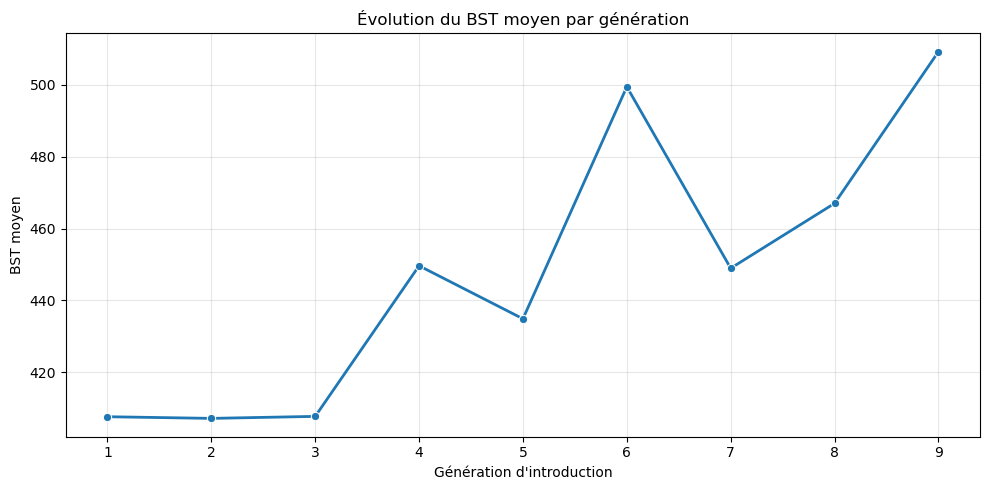

,generation,mean,median,count
0,1,407.64,405.0,151
1,2,407.18,415.0,100
2,3,407.74,420.0,142
3,4,449.65,480.0,117
4,5,434.9,464.0,165
5,6,499.47,500.0,139
6,7,448.96,476.0,161
7,8,467.02,490.0,185
8,9,509.23,550.0,197


In [23]:

# Calcul des statistiques descriptives par génération
bst_generation = (
    df_analyse.groupby("generation")["bst"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

# Graphique
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=bst_generation,
    x="generation",
    y="mean",
    marker="o",
    linewidth=2
)

plt.title("Évolution du BST moyen par génération")
plt.xlabel("Génération d'introduction")
plt.ylabel("BST moyen")
plt.xticks(range(1, 10))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(bst_generation.round(2))


## 10.2. Distribution du BST selon les générations

Nous étudions la distribution du BST pour chaque génération
afin de compléter l'analyse des moyennes.

Les boîtes à moustaches permettent de comparer les médianes,
la dispersion et les valeurs atypiques entre générations.

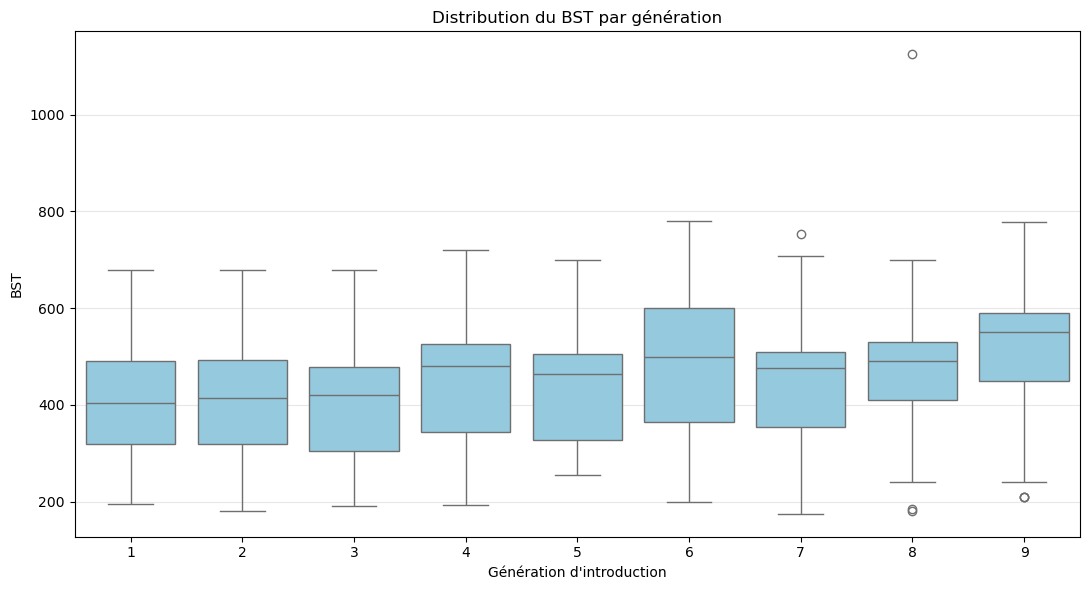

,count,mean,std,min,25%,50%,75%,max
generation,,,,,,,,
1,151.0,407.64,99.88,195.0,320.0,405.0,490.0,680.0
2,100.0,407.18,112.46,180.0,319.5,415.0,492.5,680.0
3,142.0,407.74,116.34,190.0,305.75,420.0,478.75,680.0
4,117.0,449.65,118.19,194.0,345.0,480.0,525.0,720.0
5,165.0,434.9,107.93,255.0,328.0,464.0,505.0,700.0
6,139.0,499.47,138.34,200.0,365.5,500.0,600.0,780.0
7,161.0,448.96,115.78,175.0,355.0,476.0,510.0,754.0
8,185.0,467.02,119.63,180.0,410.0,490.0,530.0,1125.0
9,197.0,509.23,125.32,210.0,450.0,550.0,590.0,778.0


In [24]:

# Distribution du BST selon la génération
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df_analyse,
    x="generation",
    y="bst",
    color="skyblue",
    showfliers=True
)

plt.title("Distribution du BST par génération")
plt.xlabel("Génération d'introduction")
plt.ylabel("BST")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Résumé de la distribution
display(
    df_analyse.groupby("generation")["bst"]
    .describe()
    .round(2)
)


## 10.3. Évolution des six statistiques individuelles

On va comparer HP, attaque, défense, attaque spéciale, défense spéciale et vitesse.

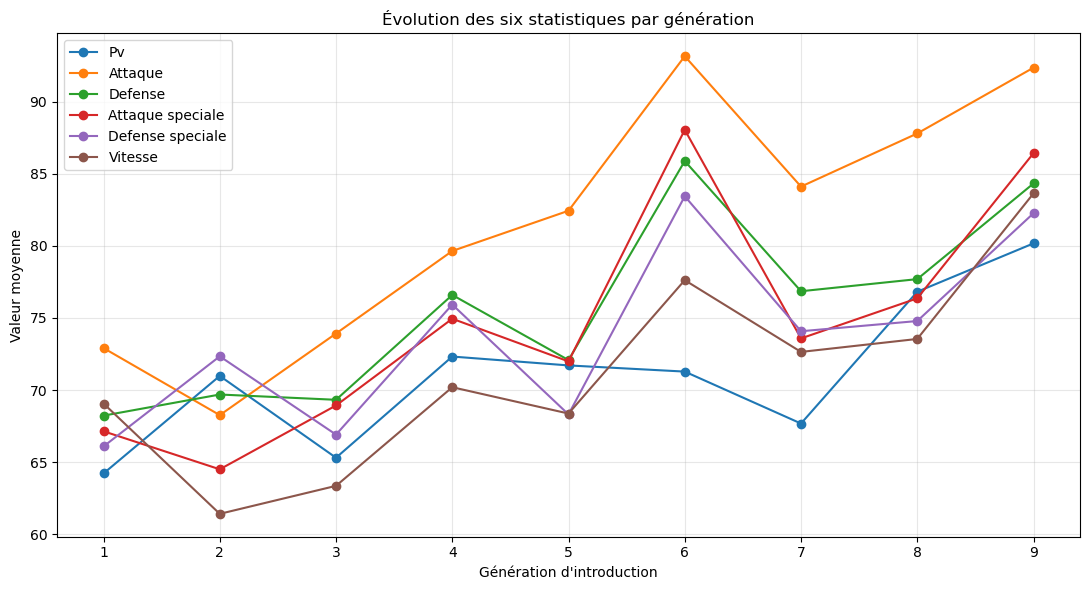

In [25]:

# Moyenne des six statistiques par génération
stats = [
    "pv", "attaque", "defense",
    "attaque_speciale", "defense_speciale", "vitesse"
]

moyennes_stats = (
    df_analyse.groupby("generation")[stats]
    .mean()
)

# Une courbe par statistique
plt.figure(figsize=(11, 6))

for stat in stats:
    plt.plot(
        moyennes_stats.index,
        moyennes_stats[stat],
        marker="o",
        label=stat.replace("_", " ").capitalize()
    )

plt.title("Évolution des six statistiques par génération")
plt.xlabel("Génération d'introduction")
plt.ylabel("Valeur moyenne")
plt.xticks(range(1, 10))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Les six statistiques augmentent globalement entre les générations I et IX, malgré des fluctuations importantes. L'attaque physique domine généralement, tandis que les PV évoluent de manière moins régulière.

La génération VI se distingue par un pic marqué, potentiellement lié à l'introduction des Méga-Évolutions.

## 10.4. Évolution de la spécialisation

La spécialisation mesure le déséquilibre entre les six statistiques d'un Pokémon. Un Pokémon spécialisé possède certaines statistiques nettement plus élevées que d'autres.

On la mesure par le coefficient de variation :

$$
CV = \frac{\text{Écart-type des six statistiques}}{\text{Moyenne des six statistiques}}
$$

Plus le CV est élevé, plus le Pokémon est spécialisé. Nous étudions son évolution pour déterminer si les générations récentes présentent des profils statistiques plus déséquilibrés.

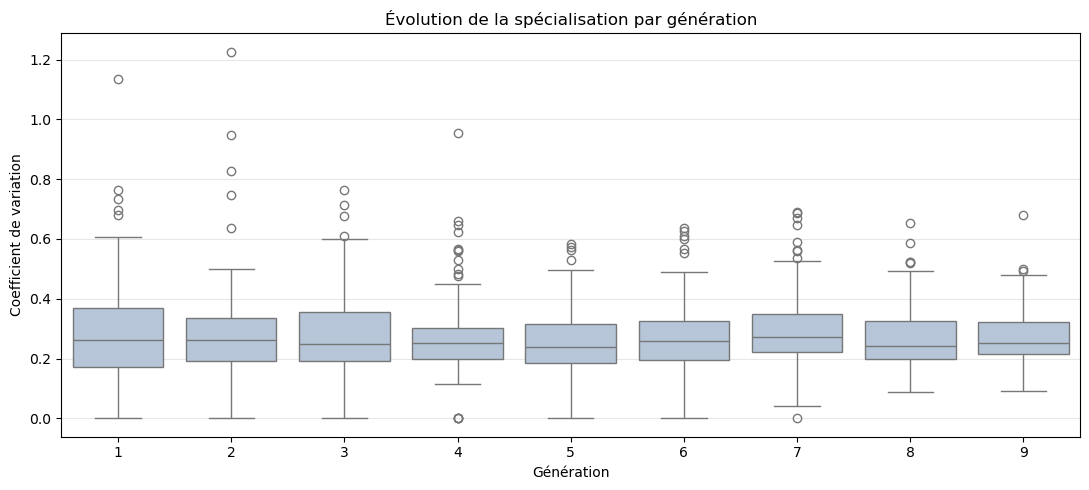

In [26]:
# Les six statistiques de base
stats = [
    "pv", "attaque", "defense",
    "attaque_speciale", "defense_speciale", "vitesse"
]

# Calcul du coefficient de variation pour chaque Pokémon
df_analyse["specialisation"] = (
    df_analyse[stats].std(axis=1, ddof=0)
    / df_analyse[stats].mean(axis=1)
)

# Visualisation de la distribution par génération
plt.figure(figsize=(11, 5))

sns.boxplot(
    data=df_analyse,
    x="generation",
    y="specialisation",
    color="lightsteelblue"
)

plt.title("Évolution de la spécialisation par génération")
plt.xlabel("Génération")
plt.ylabel("Coefficient de variation")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

La spécialisation reste relativement stable au fil des générations, avec des médianes proches de 0,25. Quelques Pokémon présentent des profils très spécialisés, notamment dans les premières générations, mais aucune tendance nette à la hausse ne se dégage.

## 10.5. Influence des Méga-Évolutions

Nous comparons l'évolution du BST moyen avec et sans les
Méga-Évolutions afin d'évaluer leur contribution aux
différences observées entre générations.

Nombre de Méga-Évolutions : 97


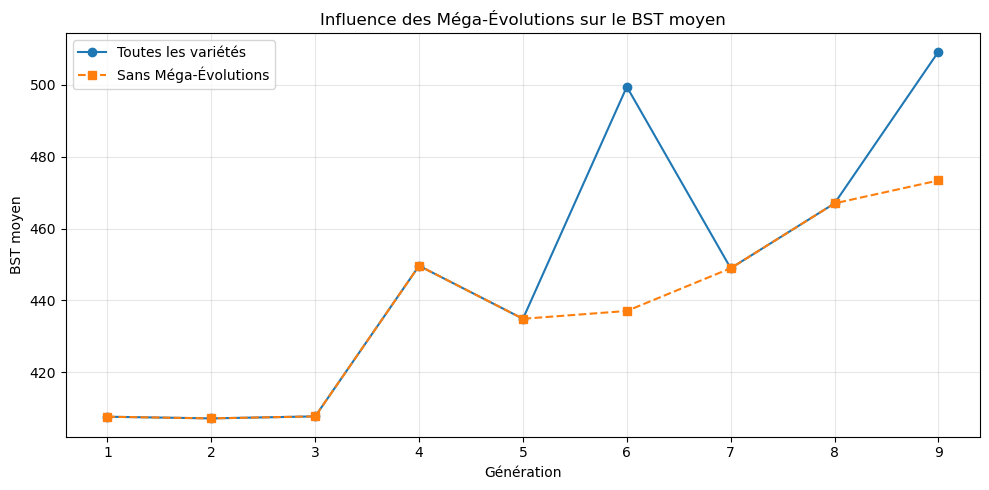

In [28]:
# Identification des Méga-Évolutions
mega = df_analyse["is_mega"].astype(str).str.lower().isin(["true", "1"])

print("Nombre de Méga-Évolutions :", mega.sum())

# Moyennes avec et sans Méga-Évolutions
bst_tous = df_analyse.groupby("generation")["bst"].mean()

bst_sans_mega = (
    df_analyse.loc[~mega]
    .groupby("generation")["bst"]
    .mean()
)

# Visualisation
plt.figure(figsize=(10, 5))

plt.plot(bst_tous.index, bst_tous,
         marker="o", label="Toutes les variétés")

plt.plot(bst_sans_mega.index, bst_sans_mega,
         marker="s", linestyle="--",
         label="Sans Méga-Évolutions")

plt.title("Influence des Méga-Évolutions sur le BST moyen")
plt.xlabel("Génération")
plt.ylabel("BST moyen")
plt.xticks(range(1, 10))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Les Méga-Évolutions expliquent une grande partie des pics de BST observés aux générations VI et IX. Sans elles, l'évolution est plus progressive, ce qui montre leur influence sur la puissance moyenne des Pokémon.